# Bays (2014) Figure 1 Equivalence - Metric Heatmaps

**Key design:**
- `Population` class (`core.population`) handles encode/decode
- Circular stats (`circular_variance_fisher`, `circular_kurtosis_fisher`) live in `core.metrics`
- Single `MODEL` knob (`gp` / `vm` / `bays`)
- Analysis helpers live in core modules; the notebook defines none inline


## What changed in this version (thesis corrections)

The experiment is unchanged: the same (ω, γ) grid (20 × 20, logarithmic), the same
set sizes {1, 2, 4, 8} and L = 8 locations, the same `Population` encoder and decoder,
the same metrics (circular variance, circular kurtosis, variance exponent), the same
reference gain line (γ_ref = 114.73 Hz) and the same naive-prediction equivalence test.
M stays at 1000: this experiment sweeps parameters and fits nothing.

What changed, and why:

1. **Population seeds (Correction 3).** The heatmaps are computed at `N_SEEDS`
   independent population draws and averaged. The total number of trials per pixel is
   unchanged (10,000), now split across the draws (`N_TRIALS_PER_SEED` = 1,000), so the
   runtime is about the same as before. Seed 0 uses the original seeds. Each population
   is built once per (ω, seed) and reused for every set size; the original rebuilt the
   same population (same seed) for each set size, so the results are identical.
   Each seed is cached as it finishes, so the run can resume.
2. **Equivalence test with uncertainty.** ρ and rMAE are computed per seed and reported
   as means with 95% confidence intervals. A paired test asks, for each set size and
   statistic, whether the model departs from the naive prediction on average across ω.
3. **Figures (Correction 7).** The equivalence figure (thesis Fig 5) shows means with 95%
   bands, and every y-axis has at least two labelled ticks. A new appendix figure maps
   how much each heatmap pixel varies between population draws. Each figure cell prints
   which axes are log for the caption.
4. **Gamma sampler** for the main text (the last cached run used sparse-sharp).
5. **Housekeeping.** Results are saved under `simulated_experiments/bays_2014/result_data`
   (the old path pointed at a folder that no longer exists).

#### 💾 Simulation Cache

The expensive simulation cell (the multi-set-size heatmap) saves its output to `./_sim_cache/` keyed on a hash of all relevant parameters (M, N_THETA, N_TRIALS, grid params, MODEL, seeds, …).

**Workflow for re-running this notebook:**

1. The first run populates the cache (slow).
2. Subsequent runs — including kernel restarts — skip the simulation and just load the arrays from disk (fast). All downstream plotting / analysis cells can then be edited and re-run in seconds.
3. If you change any simulation parameter (e.g. `M`, `N_TRIALS`, `MODEL`), the cache key changes automatically and the affected cell recomputes.
4. To force a fresh recompute without changing parameters, set `FORCE_RECOMPUTE = True` in the imports cell, or delete the relevant `.npz` file in `_sim_cache/`.
5. The helper `list_cache()` (called automatically at the top) prints what's currently stored.

**What's cached:**

| Cell | Cache name | Contents |
|------|------------|----------|
| Multi-set-size heatmap | `multi_heatmap` | per-`l` `var`/`kur`/`exp` grids |


#### Environment, Bays `Population` import & simulation cache

In [25]:
import sys
from pathlib import Path
PROJECT_ROOT = str(Path.cwd().parents[1])
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time
import hashlib
import json as _json
import os

# ---- Import the Bays population model (encode -> DN -> spike -> ML decode) ----
from core.population import Population

print(f"Project root: {PROJECT_ROOT}")

# ============================================================
# Output directory for this run's deliverable results
# ============================================================
# A fresh timestamped folder under the project result_data tree.
# Figures (and any saved arrays) for this run are written here so
# successive runs never overwrite each other. This is separate from
# the _sim_cache/ below, which is the hash-keyed recompute cache.
import datetime
RESULT_BASE    = Path(PROJECT_ROOT) / 'simulated_experiments' / 'bays_2014' / 'result_data'
assert RESULT_BASE.parent.is_dir(), f'Expected the bays_2014 folder at {RESULT_BASE.parent}'
EXPERIMENT_TAG = 'experiment_1'
# OUTPUT_DIR is built in the experiment-control section below, once
# M / DISTRIBUTION / MODEL are known, so the folder name encodes the run.

# ============================================================
# Simulation cache infrastructure
# ============================================================
# Expensive simulation cells (the main heatmap and the multi-set-size
# heatmap) save their results to disk keyed on the parameters used.
# Downstream plotting / analysis cells then load these arrays and run
# instantly. To force a fresh recompute, set FORCE_RECOMPUTE = True
# below, or delete the relevant .npz file in CACHE_DIR.

CACHE_DIR = Path.cwd() / "_sim_cache"
CACHE_DIR.mkdir(exist_ok=True)

FORCE_RECOMPUTE = False   # set True to ignore cache and recompute everything

def _hash_key(params: dict) -> str:
    """Deterministic short hash of a dict of parameters."""
    blob = _json.dumps(params, sort_keys=True, default=str).encode()
    return hashlib.md5(blob).hexdigest()[:12]

def cache_path(name: str, params: dict) -> Path:
    """Return the .npz cache path for a named computation + its params."""
    return CACHE_DIR / f"{name}__{_hash_key(params)}.npz"

def load_cache(name: str, params: dict):
    """Return dict of arrays if cache hit, else None."""
    if FORCE_RECOMPUTE:
        return None
    p = cache_path(name, params)
    if not p.exists():
        return None
    try:
        with np.load(p, allow_pickle=True) as data:
            return {k: data[k] for k in data.files}
    except Exception as e:
        print(f"  [cache] failed to load {p.name}: {e}")
        return None

def save_cache(name: str, params: dict, arrays: dict):
    """Save arrays to cache with embedded params metadata."""
    p = cache_path(name, params)
    # Stash params alongside the arrays for traceability.
    payload = dict(arrays)
    payload["_params_json"] = np.array(_json.dumps(params, default=str))
    np.savez_compressed(p, **payload)
    print(f"  [cache] saved {p.name}  ({p.stat().st_size / 1e6:.2f} MB)")

def list_cache():
    """Print all cache entries with their parameter hash."""
    files = sorted(CACHE_DIR.glob("*.npz"))
    if not files:
        print(f"  [cache] (empty) {CACHE_DIR}")
        return
    print(f"  [cache] {CACHE_DIR}:")
    for f in files:
        size_mb = f.stat().st_size / 1e6
        print(f"    {f.name}  ({size_mb:.2f} MB)")

list_cache()

Project root: /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model
  [cache] /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/_sim_cache:
    multi_heatmap__023bfa85d1fb.npz  (0.04 MB)
    multi_heatmap__1cb0a8ac87e8.npz  (0.04 MB)
    multi_heatmap__445f3c3919d4.npz  (0.04 MB)
    multi_heatmap__5464e2d6024a.npz  (0.04 MB)
    multi_heatmap__a3a23bd63b9f.npz  (0.04 MB)
    multi_heatmap__e5dd54b59007.npz  (0.04 MB)
    multi_heatmap_seed__00b81f4139a1.npz  (0.04 MB)
    multi_heatmap_seed__25674ed99bf2.npz  (0.04 MB)
    multi_heatmap_seed__438d47e23133.npz  (0.04 MB)
    multi_heatmap_seed__5541e6267863.npz  (0.04 MB)
    multi_heatmap_seed__582e6a007062.npz  (0.04 MB)
    multi_heatmap_seed__5ad217062e12.npz  (0.04 MB)
    multi_heatmap_seed__601c536622fb.npz  (0.04 MB)
    multi_heatmap_seed__60238e853aa2.npz  (0.04 MB)
    multi_heatmap_seed__6d9484b96646.npz  (0.04 MB)
  

#### Circular-error metrics (imported from `core.metrics`)

In [26]:
# Circular-error metrics now live in core.metrics (single source of truth).
# See core/metrics.py for the Fisher (1995) definitions used by Bays (2014).
from core.metrics import circular_variance_fisher, circular_kurtosis_fisher


#### Sanity check — `Population.run_trials` is vectorised

In [27]:
import inspect
src = inspect.getsource(Population.run_trials)
print("Vectorised" if "log_r_pre" in src else "Sequential (OLD)")

Vectorised


### Parameters

**Mapping:** Bays's tuning f = 1/omega gives omega = lambda^2, so lambda = sqrt(omega).
- Small omega (broad tuning) -> small lambda
- Large omega (narrow tuning) -> large lambda

## GP Experiment Control

Three knobs govern every population built in this notebook (the L>1 multi-set-size sweep and the diagnostics below). Flipping any of them changes the simulation-cache key, so a matching cached result is loaded or a fresh one is computed automatically.

**`M`** is the population size. Suggested values: `100` (fast, primary reference), `1000` (default), `10000` (large-population asymptotic).

**`DISTRIBUTION`** chooses how lengthscales are sampled across locations inside the GP / VM forward model: `'folded_normal'`, `'gamma'`, or `'M_sparse_broad'`. It affects the `gp` and `vm` models; the `bays` model uses parametric von Mises tuning and ignores it.

**`MODEL`** selects the encoder: `'gp'` (Gaussian-process tuning, width = √ω), `'vm'` (von Mises tuning, width = ω), or `'bays'` (the parametric Bays baseline, homogeneous, single location with the γ/l activity-cap shortcut).

`'M_sparse_broad'` is the multi-broad-location variant of `population.py`'s `sparse_broad` sampler — `N_HIGH` locations are drawn 'broad' and the rest 'sharp' (set `N_HIGH = 1` for the one-hot case). It is resolved to the underlying `sparse_broad` method via `_DISTRIBUTION_MAP` in the control cell below.

#### Experiment control — population size `M` & lengthscale sampler

In [28]:
# === GP EXPERIMENT CONTROL — set M and lengthscale sampler for this run ===
# Flags governing every GP Population built in this notebook. Cached
# heatmaps automatically pick this up via the cache key, so flipping
# either flag forces a recompute (or loads a matching cached result).

M            = 1000               # 100 / 1000 / 10000
DISTRIBUTION = 'M_sparse_broad'           # 'folded_normal' | 'gamma' | 'M_sparse_broad'
                                 #   gamma for the main text; the others for the appendix
MODEL        = 'gp'              # 'gp' | 'vm' | 'bays'  (encoder / tuning model)

assert DISTRIBUTION in ('folded_normal', 'gamma', 'M_sparse_broad'), (
    f"DISTRIBUTION must be one of 'folded_normal', 'gamma', "
    f"'M_sparse_broad', got {DISTRIBUTION!r}"
)
assert MODEL in ('gp', 'vm', 'bays'), f"MODEL must be gp/vm/bays, got {MODEL!r}"

# --- Sparse sampler knob ----------------------------------------------
# The 'M_sparse_broad' label selects population.py's sparse sampler
# (canonical name 'sparse_sharp'). Despite the legacy "broad" in the
# label, the sampler makes the N_HIGH selected locations SHARP:
#     selected N_HIGH locations : lambda ~ base_lengthscale / high_multiplier  (sharp)
#     all other locations       : lambda ~ base_lengthscale                    (broader background)
# high_multiplier is not set here, so the sampler default (3.0) is used.
# N_HIGH = 1 is the one-hot case; N_HIGH > 1 sharpens several locations.
N_HIGH = 1

# --- Resolve the notebook label to (method, kwargs) for Population() ----
# folded_normal / gamma pass straight through. 'M_sparse_broad' maps onto
# the canonical 'sparse_sharp' method (identical to the 'sparse_broad'
# alias) with n_high forwarded; Population() -> generate_neuron_population
# -> generate_location_dependent_lengthscales all forward n_high.
_DISTRIBUTION_MAP = {
    'folded_normal':  ('folded_normal', {}),
    'gamma':          ('gamma',         {}),
    'M_sparse_broad': ('sparse_sharp',  {'n_high': N_HIGH}),
}
GP_METHOD, GP_METHOD_KWARGS = _DISTRIBUTION_MAP[DISTRIBUTION]

print(f'=== GP experiment control ===')
print(f'  M                = {M}')
print(f'  MODEL            = {MODEL!r}')
print(f'  DISTRIBUTION     = {DISTRIBUTION!r}')
print(f'  -> GP_METHOD     = {GP_METHOD!r}')
print(f'  -> extra kwargs  = {GP_METHOD_KWARGS}')

=== GP experiment control ===
  M                = 1000
  MODEL            = 'gp'
  DISTRIBUTION     = 'M_sparse_broad'
  -> GP_METHOD     = 'sparse_sharp'
  -> extra kwargs  = {'n_high': 1}


#### Simulation grid — width ω × gain γ

In [29]:
# M is set by the experiment-control cell above.
N_THETA = 256      # Orientation grid resolution
N_TRIALS = 10000   # trials per pixel IN TOTAL (unchanged)
N_SEEDS  = 10      # population seeds (Correction 3)
N_TRIALS_PER_SEED = N_TRIALS // N_SEEDS   # 1,000 per seed: same total as before
SEED_STRIDE = 1_000_000                   # replicate s shifts every seed by s * SEED_STRIDE
T_D = 0.1          # Decoding window (s)
SIGMA_SQ = 1e-6    # Semi-saturation constant

# ---- Width (x-axis): omega = lambda^2 ----
OMEGA_RANGE = (0.125, 2.5)
LAMBDA_RANGE = (np.sqrt(OMEGA_RANGE[0]),    # 0.354 (broad, low omega)
                np.sqrt(OMEGA_RANGE[1]))     # 1.581 (narrow, high omega)

# ---- Gain (y-axis): gamma_total = gamma_mean * M ----
GAMMA_TOTAL_RANGE = (0.25, 4096)   # Hz, total population gain
GAMMA_RANGE = (GAMMA_TOTAL_RANGE[0] / M,
               GAMMA_TOTAL_RANGE[1] / M)

N_GRID = 20

# Build grids
lambdas = np.logspace(np.log2(LAMBDA_RANGE[0]), np.log2(LAMBDA_RANGE[1]), N_GRID, base=2)
omegas = lambdas**2

gammas = np.logspace(np.log2(GAMMA_RANGE[0]), np.log2(GAMMA_RANGE[1]), N_GRID, base=2)
gammas_total = gammas * M

print(gammas_total)


print(f"Grid: {N_GRID}x{N_GRID}, {N_TRIALS:,} trials per pixel in total ({N_SEEDS} seeds x {N_TRIALS_PER_SEED:,})")
print(f"lambda range:       [{LAMBDA_RANGE[0]:.3f}, {LAMBDA_RANGE[1]:.3f}]")
print(f"omega = lambda^2:   [{omegas[0]:.3f}, {omegas[-1]:.3f}]")
print(f"gamma_total range:  [{gammas_total[0]:.2f}, {gammas_total[-1]:.1f}] Hz")

[2.50000000e-01 4.16631003e-01 6.94325571e-01 1.15711024e+00
 1.92835200e+00 3.21364491e+00 5.35561640e+00 8.92526334e+00
 1.48741657e+01 2.47881543e+01 4.13100543e+01 6.88441975e+01
 1.14730508e+02 1.91201147e+02 3.18641303e+02 5.31023383e+02
 8.84963219e+02 1.47481245e+03 2.45781037e+03 4.09600000e+03]
Grid: 20x20, 10,000 trials per pixel in total (10 seeds x 1,000)
lambda range:       [0.354, 1.581]
omega = lambda^2:   [0.125, 2.500]
gamma_total range:  [0.25, 4096.0] Hz


#### Encoder toggle & reference Bays operating point

In [30]:
# ---- Encoder / run configuration ----
# MODEL (gp / vm / bays) is set in the experiment-control cell above.
SEED = 42

# ---- Reference Bays operating point (group-mean ML fit, Bays 2014 Fig 2b) ----
# The fixed (omega, gamma) at which the equivalence test is run. Nothing here
# is fitted -- figure 1 uses Bays's published values directly.
GAMMA_TOTAL_FITTED = 119.0   # Hz -- total population gain
OMEGA_FITTED       = 0.52    # tuning width (group mean)
SET_SIZES          = [1, 2, 4, 8]
gamma_fitted = GAMMA_TOTAL_FITTED / M

# ---- Output directory for this run's deliverables --------------------
#   result_data / experiment_1 / <date> / <distribution>_<M>_<model> / <time>
# Mirrors the Experiment 2/3 scheme so the folder name is self-describing.
_date = datetime.datetime.now().strftime('%Y%m%d')
_time = datetime.datetime.now().strftime('%H%M%S')
OUTPUT_DIR = (RESULT_BASE / EXPERIMENT_TAG / _date /
              f'{DISTRIBUTION}_{M}_{MODEL}' / _time)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"MODEL={MODEL}, SEED={SEED}")
print(f"gamma_total = {GAMMA_TOTAL_FITTED} Hz  (gamma_mean = {gamma_fitted:.6f} Hz/neuron)")
print(f"OUTPUT_DIR = {OUTPUT_DIR}")

MODEL=gp, SEED=42
gamma_total = 119.0 Hz  (gamma_mean = 0.119000 Hz/neuron)
OUTPUT_DIR = /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_1/20261021/M_sparse_broad_1000_gp/090443


## L > 1, HeatMap Creation

**Goal:** Test whether the Bays equivalence (l items at γ ≡ 1 item at γ/l) holds for the GP model.

**Design:**
- **4 rows** (l = 1, 2, 4, 8) × **3 columns** (variance, kurtosis, exponent)
- Each row is a full (ω, γ) heatmap computed by running the **actual** multi-item pipeline at that set size
- All rows use the **same underlying population** (same GP samples) per ω column
- **Row 1 (l=1):** horizontal lines at γ\_eff = γ\_total/l mark the Bays predictions
- **Rows 2–4:** single black line at γ\_total = 114.73 Hz (grid index 12)

**Quantitative test (at γ\_total = 114.73 Hz):**
- **Vector A** (Bays prediction): l=1 heatmap row at γ\_eff = γ\_total/l
- **Vector B** (actual): l-th heatmap row at γ\_total
- Compare via Pearson correlation and mean absolute error

In Bays's model, A = B exactly. In the GP model, deviations reveal how mixed selectivity and shared populations create a more nuanced resource division.

#### Compute per-set-size (ω, γ) heatmaps at every population seed  ·  l = 1, 2, 4, 8

Same computation as before, repeated at `N_SEEDS` population draws with
`N_TRIALS_PER_SEED` trials per pixel each. `heatmaps[l]` holds the mean over seeds
(geometric mean for variance, arithmetic mean for kurtosis and exponent), which is what
the heatmap figure draws; `heatmaps_seeds[l]` keeps every seed for the confidence
intervals.

In [31]:
# ---- Multi-set-size heatmap computation, at every population seed ----
from tqdm.auto import tqdm

N_LOCATIONS_HEATMAP = 8
SET_SIZES_HEATMAP = [1, 2, 4, 8]
GAMMA_REF_IDX = 12  # γ_total = 114.73 Hz (exact grid point)
SEED_MULTI_HEATMAP = 42
KEYS = ('var', 'kur', 'exp')

print(f"Reference γ_total = {gammas_total[GAMMA_REF_IDX]:.2f} Hz (index {GAMMA_REF_IDX})")
print(f"Set sizes: {SET_SIZES_HEATMAP}")
print(f"Grid: {N_GRID}×{N_GRID}; {N_SEEDS} seeds × {N_TRIALS_PER_SEED:,} trials per pixel")
print(f"Model: {MODEL}   Sampler: {DISTRIBUTION}   M = {M}")
print()


def _seed_params(s):
    """Cache key for one seed (any parameter change gives a new key)."""
    return {
        "M": M, "N_THETA": N_THETA, "N_TRIALS_PER_SEED": N_TRIALS_PER_SEED,
        "T_D": T_D, "SIGMA_SQ": SIGMA_SQ, "N_GRID": N_GRID,
        "OMEGA_RANGE": list(OMEGA_RANGE), "GAMMA_TOTAL_RANGE": list(GAMMA_TOTAL_RANGE),
        "MODEL": MODEL, "DISTRIBUTION": DISTRIBUTION, "GP_METHOD_KWARGS": GP_METHOD_KWARGS,
        "N_LOCATIONS_HEATMAP": N_LOCATIONS_HEATMAP,
        "SET_SIZES_HEATMAP": list(SET_SIZES_HEATMAP),
        "SEED_MULTI_HEATMAP": SEED_MULTI_HEATMAP, "SEED_STRIDE": SEED_STRIDE,
        "seed_index": s, "stage": "multi_heatmap_multiseed_v1",
    }


def compute_seed(s):
    """All set sizes for one population seed. Seeds are the original ones shifted
    by s * SEED_STRIDE, so seed 0 uses the original populations and trial seeds."""
    shift = s * SEED_STRIDE
    out = {l: {k: np.full((N_GRID, N_GRID), np.nan) for k in KEYS} for l in SET_SIZES_HEATMAP}
    var_half = {l: np.full((N_GRID, N_GRID), np.nan) for l in SET_SIZES_HEATMAP}
    for i, omega in enumerate(tqdm(omegas, desc=f"seed {s}: omega columns", leave=False)):
        # One population per omega column, reused for every set size (same seed as
        # the original, which rebuilt it identically for each set size).
        pop = Population(
            M, N_THETA, omega,
            tuning_type=MODEL,
            n_locations=1 if MODEL == 'bays' else N_LOCATIONS_HEATMAP,
            seed=SEED_MULTI_HEATMAP + i * 1000 + shift,
            method=GP_METHOD, **GP_METHOD_KWARGS,
        )
        for l in SET_SIZES_HEATMAP:
            for j, gam in enumerate(gammas):
                rng  = np.random.RandomState(
                    SEED_MULTI_HEATMAP + l * 100000 + i * N_GRID + j + shift)
                rng2 = np.random.RandomState(
                    SEED_MULTI_HEATMAP + l * 100000 + i * N_GRID + j + N_GRID**2 + shift)
                if pop.L == 1:
                    # Bays (L=1): γ_eff = γ/l shortcut
                    errors = pop.run_trials(N_TRIALS_PER_SEED, gam / l, T_D,
                                            set_size=1, sigma_sq=SIGMA_SQ, rng=rng)
                    errors_half = pop.run_trials(N_TRIALS_PER_SEED, gam / (2 * l), T_D,
                                                 set_size=1, sigma_sq=SIGMA_SQ, rng=rng2)
                else:
                    # GP (L>1): full multi-item pipeline
                    errors = pop.run_trials(N_TRIALS_PER_SEED, gam, T_D,
                                            set_size=l, sigma_sq=SIGMA_SQ, rng=rng)
                    errors_half = pop.run_trials(N_TRIALS_PER_SEED, gam / 2, T_D,
                                                 set_size=l, sigma_sq=SIGMA_SQ, rng=rng2)
                out[l]['var'][j, i] = circular_variance_fisher(errors)
                out[l]['kur'][j, i] = circular_kurtosis_fisher(errors)
                var_half[l][j, i] = circular_variance_fisher(errors_half)
    for l in SET_SIZES_HEATMAP:
        with np.errstate(divide='ignore', invalid='ignore'):
            ratio = np.where(var_half[l] > 1e-15, out[l]['var'] / var_half[l], np.nan)
            out[l]['exp'] = np.where(ratio > 0, np.log2(ratio), np.nan)
    return out


# heatmaps_seeds[l][key]: array (N_SEEDS, N_GRID, N_GRID)
heatmaps_seeds = {l: {k: np.full((N_SEEDS, N_GRID, N_GRID), np.nan) for k in KEYS}
                  for l in SET_SIZES_HEATMAP}
t0_all = time.time()
for s in range(N_SEEDS):
    params = _seed_params(s)
    cached = load_cache("multi_heatmap_seed", params)
    if cached is not None:
        for l in SET_SIZES_HEATMAP:
            for k in KEYS:
                heatmaps_seeds[l][k][s] = cached[f"l{l}_{k}"]
        print(f"  seed {s}: [cache HIT]")
        continue
    t0 = time.time()
    res = compute_seed(s)
    for l in SET_SIZES_HEATMAP:
        for k in KEYS:
            heatmaps_seeds[l][k][s] = res[l][k]
    save_cache("multi_heatmap_seed", params,
               {f"l{l}_{k}": res[l][k] for l in SET_SIZES_HEATMAP for k in KEYS})
    print(f"  seed {s}: done in {time.time() - t0:.0f}s  (total {time.time() - t0_all:.0f}s)")
print(f"\nAll {N_SEEDS} seeds ready in {time.time() - t0_all:.0f}s")

# Mean over seeds: what the heatmap figure draws.
def _seed_mean(stack, key):
    with np.errstate(divide='ignore', invalid='ignore'):
        if key == 'var':                                   # positive, log colour scale
            return np.exp(np.nanmean(np.log(np.where(stack > 0, stack, np.nan)), axis=0))
        return np.nanmean(stack, axis=0)

heatmaps = {l: {k: _seed_mean(heatmaps_seeds[l][k], k) for k in KEYS}
            for l in SET_SIZES_HEATMAP}
print("heatmaps[l] = mean over seeds (geometric for variance); heatmaps_seeds[l] = every seed.")

Reference γ_total = 114.73 Hz (index 12)
Set sizes: [1, 2, 4, 8]
Grid: 20×20; 10 seeds × 1,000 trials per pixel
Model: gp   Sampler: M_sparse_broad   M = 1000



seed 0: omega columns:   0%|          | 0/20 [00:00<?, ?it/s]

  [cache] saved multi_heatmap_seed__c1cbe6f5f156.npz  (0.04 MB)
  seed 0: done in 629s  (total 629s)


seed 1: omega columns:   0%|          | 0/20 [00:00<?, ?it/s]

  [cache] saved multi_heatmap_seed__de529bde873a.npz  (0.04 MB)
  seed 1: done in 622s  (total 1251s)


...

  [cache] saved multi_heatmap_seed__4b5b6c5937e5.npz  (0.04 MB)
  seed 7: done in 596s  (total 4881s)


seed 8: omega columns:   0%|          | 0/20 [00:00<?, ?it/s]

  [cache] saved multi_heatmap_seed__221adb1272f4.npz  (0.04 MB)
  seed 8: done in 593s  (total 5474s)


seed 9: omega columns:   0%|          | 0/20 [00:00<?, ?it/s]

  [cache] saved multi_heatmap_seed__9ad324510147.npz  (0.04 MB)
  seed 9: done in 595s  (total 6069s)

All 10 seeds ready in 6069s
heatmaps[l] = mean over seeds (geometric for variance); heatmaps_seeds[l] = every seed.


### L > 1, HeatMap Plotting

- **Row 1 (l=1):** single-item heatmap + horizontal lines at γ/l for l=1,2,4,8
- **Rows 2–4:** actual multi-item heatmaps + black line at γ\_total = 114.73 Hz
- Bays's prediction: row l at the black line should match row 1 at the l-th horizontal line

#### Render the 4×3 heatmap figure

Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_1/20261021/M_sparse_broad_1000_gp/090443/fig1_multisetsize_gp_M1000_M_sparse_broad_10seeds.png
Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_1/fig_1_l_n_M_sparse_broad.png
  For the caption: width and gain axes are logarithmic; the variance and kurtosis colour scales are logarithmic, the exponent scale linear. Each pixel is the mean over 10 population seeds (1,000 trials each; geometric mean for variance).


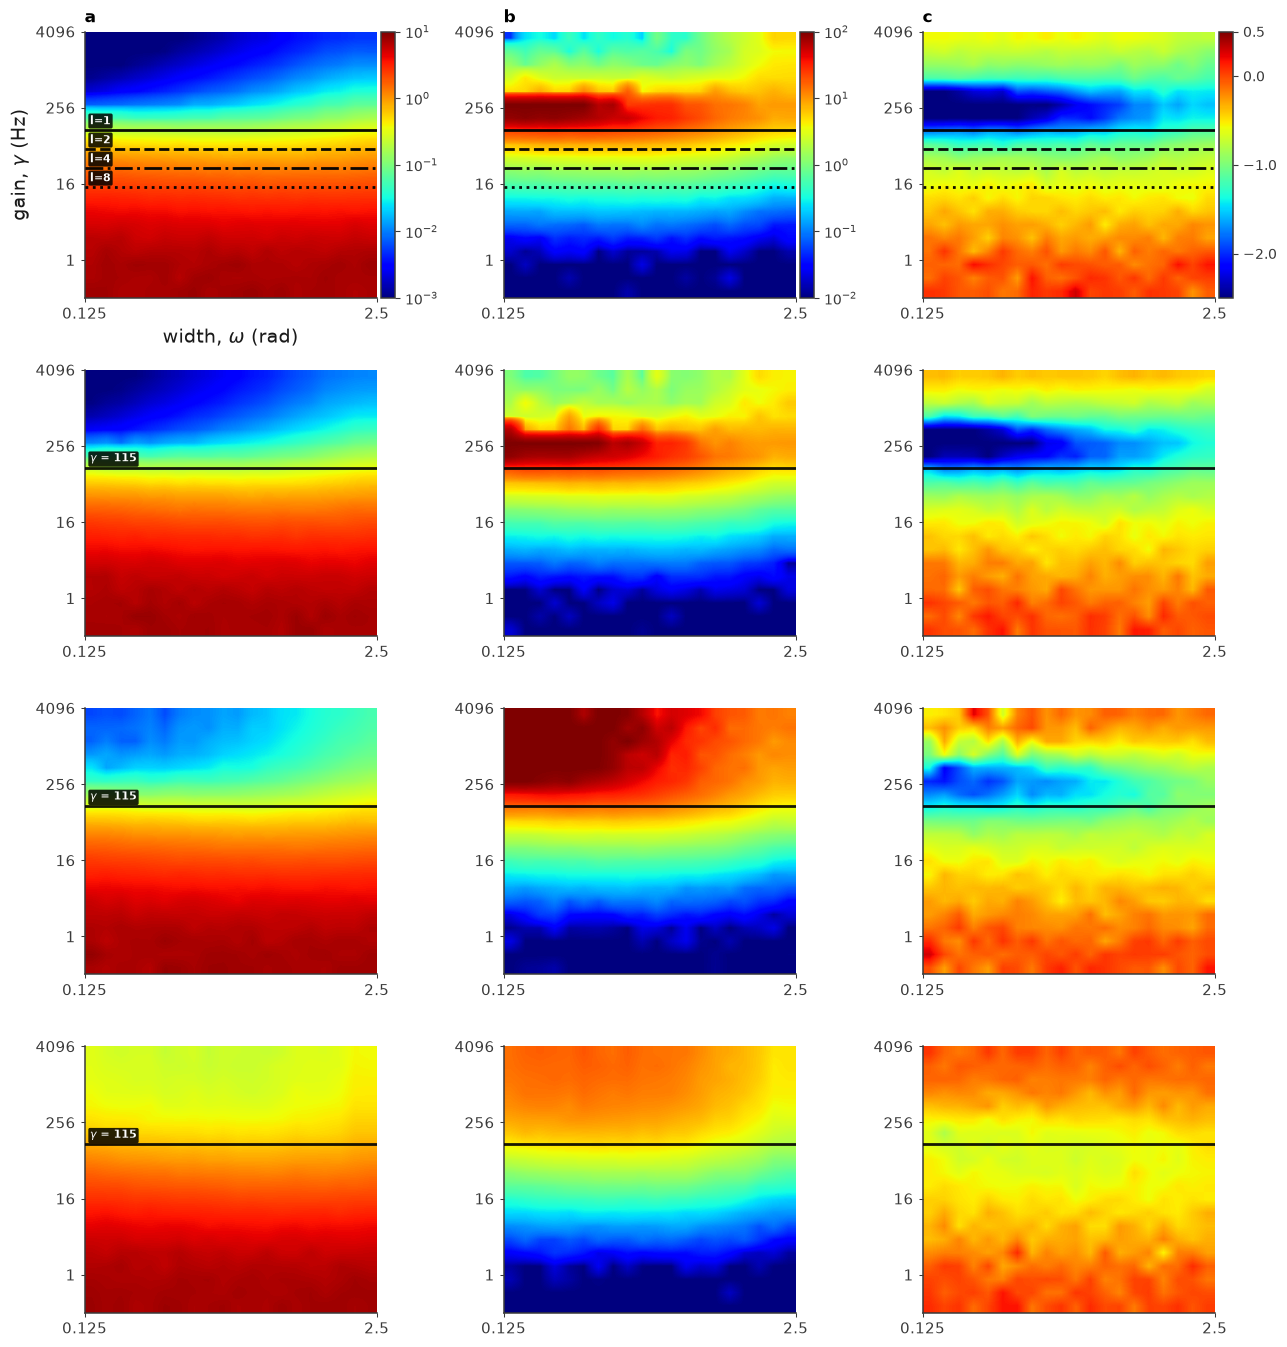

In [32]:
import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib as mpl

# --- Thesis font: match the reference figure (DejaVu Sans). ---
mpl.rcParams.update({
    'font.family':     'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'pdf.fonttype':    42,
    'ps.fonttype':     42,
})

# ---- 4-row × 3-column figure ----
ext = [
    np.log2(omegas[0]), np.log2(omegas[-1]),
    np.log2(gammas_total[0]), np.log2(gammas_total[-1]),
]

gamma_ref = gammas_total[GAMMA_REF_IDX]

VAR_VMIN, VAR_VMAX = 0.001, 10
KUR_VMIN, KUR_VMAX = 0.01,  100
EXP_VMIN, EXP_VMAX = -2.5, 0.5

# y (gain gamma) and x (width omega) are both LOG axes: values pass through
# np.log2 before imshow; ticks sit at log2 positions, labelled with real values.
Y_TICKS = np.array([1, 16, 256, 4096])   # range filter drops any outside the gamma range
YTICK_FONTSIZE = 11
XTICK_FONTSIZE = 11
CBAR_FONTSIZE  = 10          # heatmap colour-scale tick labels

def fmt_ax_multi(ax, is_key):
    """Aesthetics only. Tick positions/marks AND tick-number labels appear on
    every panel; only the top-left ('key') panel adds the omega / gamma axis
    labels, which act as a shared legend for the grid."""
    ax.grid(False)

    # x tick numbers on every panel; axis label on the key panel alone.
    ax.set_xticks([np.log2(omegas[0]), np.log2(omegas[-1])])
    ax.set_xticklabels([f'{omegas[0]:g}', f'{omegas[-1]:g}'],
                       fontsize=XTICK_FONTSIZE)
    if is_key:
        ax.set_xlabel(r'width, $\omega$ (rad)', fontsize=14)

    # y tick numbers on every panel; axis label on the key panel alone.
    yt = Y_TICKS[(Y_TICKS >= gammas_total[0] * 0.9) &
                 (Y_TICKS <= gammas_total[-1] * 1.1)]
    ax.set_yticks(np.log2(yt))
    ax.set_yticklabels([f'{v:g}' for v in yt], fontsize=YTICK_FONTSIZE)
    if is_key:
        ax.set_ylabel(r'gain, $\gamma$ (Hz)', fontsize=14)

    # Tick marks visible on every panel.
    ax.tick_params(axis='both', length=3, width=0.75)


def add_cbar_slot(ax, im=None, log=False, tick_labelsize=CBAR_FONTSIZE, ticks=None):
    """Reserve an identical colorbar slot on every panel. Fill only when im
    is given. `ticks` lets us thin out the exponent scale."""
    cax = make_axes_locatable(ax).append_axes('right', size='5%', pad=0.04)
    if im is None:
        cax.axis('off')
        return
    cbar = fig.colorbar(im, cax=cax)
    if log:
        cbar.ax.yaxis.set_major_locator(mticker.LogLocator(base=10))
        cbar.ax.yaxis.set_minor_locator(mticker.NullLocator())
        cbar.ax.yaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10))
    elif ticks is not None:
        cbar.set_ticks(ticks)
    cbar.ax.tick_params(labelsize=tick_labelsize)

overlay_styles = {1: '-', 2: '--', 4: '-.', 8: ':'}
OVERLAY_COLOR  = 'black'
COLUMN_LETTERS = ['a', 'b', 'c']

nrows = len(SET_SIZES_HEATMAP)
fig, axes = plt.subplots(nrows, 3, figsize=(13, 3.4 * nrows))

# key, vmin, vmax, title, is_log, cbar tick size, explicit cbar ticks
# (title kept in the spec for reference but no longer drawn)
col_spec = [
    ('var', VAR_VMIN, VAR_VMAX, 'variance', True,  CBAR_FONTSIZE, None),
    ('kur', KUR_VMIN, KUR_VMAX, 'kurtosis', True,  CBAR_FONTSIZE, None),
    ('exp', EXP_VMIN, EXP_VMAX, 'exponent', False, CBAR_FONTSIZE, [0.5, 0, -1, -2]),
]

for row_idx, l in enumerate(SET_SIZES_HEATMAP):
    is_bottom = (row_idx == nrows - 1)
    is_top    = (row_idx == 0)
    data = heatmaps[l]

    for col_idx, (key, vmin, vmax, title, is_log, cbtick, cbticks) in enumerate(col_spec):
        ax = axes[row_idx, col_idx]
        norm = mcolors.LogNorm(vmin=vmin, vmax=vmax) if is_log else None
        kw = dict(norm=norm) if is_log else dict(vmin=vmin, vmax=vmax)
        im = ax.imshow(np.clip(data[key], vmin, vmax),
                       origin='lower', aspect='auto', extent=ext,
                       cmap='jet', interpolation='bilinear', **kw)

        add_cbar_slot(ax, im=im if is_top else None,
                      log=is_log, tick_labelsize=cbtick, ticks=cbticks)

        # Tick numbers on every panel; axis labels only on the top-left panel.
        fmt_ax_multi(ax, is_key=(is_top and col_idx == 0))

        # Panel letters a/b/c: top of the top row only (column identifiers).
        if is_top:
            ax.text(0.0, 1.02, COLUMN_LETTERS[col_idx],
                    transform=ax.transAxes, fontsize=12,
                    fontweight='bold', va='bottom', ha='left')

    # ---- Overlay lines (all black) ----
    for col_idx in range(3):
        ax = axes[row_idx, col_idx]
        if is_top:
            for ll in SET_SIZES_HEATMAP:
                g_eff = gamma_ref / ll
                if gammas_total[0] <= g_eff <= gammas_total[-1]:
                    y_pos = np.log2(g_eff)
                    ax.axhline(y=y_pos, color=OVERLAY_COLOR,
                               linestyle=overlay_styles[ll],
                               linewidth=2.0, alpha=0.95, zorder=5)
                    if col_idx == 0:
                        ax.text(ext[0] + 0.08, y_pos + 0.15, f'l={ll}',
                                color='white', fontsize=8, fontweight='bold',
                                va='bottom', ha='left', zorder=6,
                                bbox=dict(boxstyle='round,pad=0.15',
                                          fc=OVERLAY_COLOR, ec='none', alpha=0.85))
        else:
            y_pos = np.log2(gamma_ref)
            ax.axhline(y=y_pos, color=OVERLAY_COLOR, linestyle='-',
                       linewidth=2.0, alpha=0.9, zorder=5)
            if col_idx == 0:
                ax.text(ext[0] + 0.08, y_pos + 0.15,
                        f'$\\gamma$ = {gamma_ref:.0f}', color='white',
                        fontsize=8, fontweight='bold', va='bottom', ha='left',
                        zorder=6,
                        bbox=dict(boxstyle='round,pad=0.15',
                                  fc=OVERLAY_COLOR, ec='none', alpha=0.85))

    # (Row set-size number removed.)

plt.tight_layout()

_results_dir = OUTPUT_DIR
_l8_path = _results_dir / f'fig1_multisetsize_{MODEL}_M{M}_{DISTRIBUTION}_{N_SEEDS}seeds.png'
plt.savefig(_l8_path, dpi=150, bbox_inches='tight', pad_inches=0.4)
print(f'Saved {_l8_path}')
# Thesis copy (images/results/fig_1_l_n.png in Overleaf).
THESIS_FIG_DIR = Path(PROJECT_ROOT) / 'simulated_experiments' / 'thesis_figures' / 'experiment_1'
THESIS_FIG_DIR.mkdir(parents=True, exist_ok=True)
_thesis_l8 = THESIS_FIG_DIR / ('fig_1_l_n.png' if DISTRIBUTION == 'gamma' else f'fig_1_l_n_{DISTRIBUTION}.png')
plt.savefig(_thesis_l8, dpi=150, bbox_inches='tight', pad_inches=0.4)
print(f'Saved {_thesis_l8}')
print(f'  For the caption: width and gain axes are logarithmic; the variance and kurtosis colour '
      f'scales are logarithmic, the exponent scale linear. Each pixel is the mean over {N_SEEDS} '
      f'population seeds ({N_TRIALS_PER_SEED:,} trials each; geometric mean for variance).')
plt.show()

### Metric Calculation

**Does l items at γ ≡ 1 item at γ/l?**

For each set size l ∈ {2, 4, 8} at the reference γ\_total = 114.73 Hz, and **for each
population seed**:
- **Vector A** (naive prediction): the l = 1 heatmap interpolated at γ\_eff = γ\_total/l
- **Vector B** (model): the l-th heatmap row at γ\_total

Both vectors have N\_GRID entries (one per ω). They are compared by:
1. **Pearson correlation ρ** — do they have the same shape across ω?
2. **Relative mean absolute error** — how far apart are the values?
3. **Average departure** — B relative to A averaged over ω (the log ratio for variance,
   the difference for kurtosis and exponent), tested against zero across seeds.

Each statistic is reported as a mean with a 95% confidence interval across seeds.

#### Equivalence analysis — predicted vs measured vectors

No optimizer runs here: (ω, γ) are fixed to Bays's published values, and the "fit" quality is quantified by Pearson ρ and relative MAE between the l=1 prediction and the multi-item measurement.

In [33]:
# ---- Quantitative equivalence test (interpolated), at every population seed ----
from scipy import stats
from scipy.stats import pearsonr

gamma_ref = gammas_total[GAMMA_REF_IDX]
log2_gammas = np.log2(gammas_total)

print(f"Reference: γ_ref = {gamma_ref:.2f} Hz (grid index {GAMMA_REF_IDX})")
print(f"Model: {MODEL}   Seeds: {N_SEEDS}")
print()


def interp_row_at_gain(grid, target_gain):
    """
    Linearly interpolate a heatmap (gamma × omega) along the log2-gain axis
    at `target_gain` Hz. Returns a length-N_GRID vector over omega.
    Linear-in-log2(gamma) matches how the gain grid was constructed.
    """
    target_log = np.log2(target_gain)
    if target_log <= log2_gammas[0]:
        return grid[0, :].copy()
    if target_log >= log2_gammas[-1]:
        return grid[-1, :].copy()
    j_hi = np.searchsorted(log2_gammas, target_log)
    j_lo = j_hi - 1
    w = (target_log - log2_gammas[j_lo]) / (log2_gammas[j_hi] - log2_gammas[j_lo])
    return (1 - w) * grid[j_lo, :] + w * grid[j_hi, :]


def mean_ci(values, conf=0.95):
    """Mean over axis 0 with a t-based CI. Returns (mean, lo, hi)."""
    x = np.asarray(values, dtype=float)
    m = np.nanmean(x, axis=0)
    n = np.sum(np.isfinite(x), axis=0)
    sd = np.nanstd(x, axis=0, ddof=1)
    half = stats.t.ppf(0.5 + conf / 2, np.maximum(n - 1, 1)) * sd / np.sqrt(np.maximum(n, 1))
    return m, m - half, m + half


def holm(pvalues):
    p = np.asarray(pvalues, dtype=float)
    adjusted = np.full_like(p, np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(ok) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


target_gains = {l: gamma_ref / l for l in [2, 4, 8]}
for l, g in target_gains.items():
    print(f"  l={l}: γ_eff = γ_ref/l = {g:.3f} Hz (interpolated, no grid snapping)")
print()

quantities = [('variance', 'var'), ('kurtosis', 'kur'), ('exponent', 'exp')]
results_table = []
_p_raw = []
for l in [2, 4, 8]:
    g_eff = target_gains[l]
    row_result = {'l': l, 'g_eff': g_eff}
    for q_name, q_key in quantities:
        preds, meass, rhos, rmaes, departs = [], [], [], [], []
        for s in range(N_SEEDS):
            vp_all = interp_row_at_gain(heatmaps_seeds[1][q_key][s], g_eff)   # prediction
            vm_all = heatmaps_seeds[l][q_key][s][GAMMA_REF_IDX, :]              # model
            preds.append(vp_all)
            meass.append(vm_all)
            valid = np.isfinite(vp_all) & np.isfinite(vm_all)
            vp, vm = vp_all[valid], vm_all[valid]
            if len(vp) >= 3:
                rhos.append(pearsonr(vp, vm)[0])
                rmaes.append(np.mean(np.abs(vp - vm)) / (np.mean(np.abs(vp)) + 1e-15))
                if q_key == 'var':
                    pos = (vp > 0) & (vm > 0)
                    departs.append(np.mean(np.log(vm[pos] / vp[pos])))
                else:
                    departs.append(np.mean(vm - vp))
            else:
                rhos.append(np.nan); rmaes.append(np.nan); departs.append(np.nan)
        departs = np.asarray(departs)
        p = stats.ttest_1samp(departs[np.isfinite(departs)], 0.0).pvalue
        _p_raw.append(p)
        row_result[f'{q_name}_rho'] = mean_ci(np.asarray(rhos))
        row_result[f'{q_name}_rmae'] = mean_ci(np.asarray(rmaes))
        row_result[f'{q_name}_depart'] = mean_ci(departs)
        row_result[f'{q_name}_p'] = p
        row_result[f'{q_name}_pred_seeds'] = np.asarray(preds)
        row_result[f'{q_name}_meas_seeds'] = np.asarray(meass)
    results_table.append(row_result)

# Holm correction across all nine (set size x statistic) departure tests.
_p_adj = iter(holm(_p_raw))
for r in results_table:
    for q_name, _ in quantities:
        r[f'{q_name}_p_holm'] = next(_p_adj)

f3 = lambda t, f='.3f': f"{t[0]:{f}} [{t[1]:{f}}, {t[2]:{f}}]"
print("Mean [95% CI] across seeds")
for r in results_table:
    print(f"l = {r['l']}  (γ_eff = {r['g_eff']:.2f} Hz)")
    for q_name, q_key in quantities:
        dep = r[f'{q_name}_depart']
        dep_txt = (f"model/prediction ratio {np.exp(dep[0]):.2f} [{np.exp(dep[1]):.2f}, {np.exp(dep[2]):.2f}]"
                   if q_key == 'var' else f"model − prediction {f3(dep)}")
        print(f"  {q_name:<9} ρ {f3(r[f'{q_name}_rho'])}   rMAE {f3(r[f'{q_name}_rmae'], '.1%')}   "
              f"{dep_txt}   p (Holm) = {r[f'{q_name}_p_holm']:.2g}")
print()
print("ρ = Pearson correlation; rMAE = mean|pred − model| / mean|pred|; departure averaged over ω.")
print("Prediction = heatmaps[1] interpolated at γ_ref/l;  model = heatmaps[l] at γ_ref.")

Reference: γ_ref = 114.73 Hz (grid index 12)
Model: gp   Seeds: 10

  l=2: γ_eff = γ_ref/l = 57.365 Hz (interpolated, no grid snapping)
  l=4: γ_eff = γ_ref/l = 28.683 Hz (interpolated, no grid snapping)
  l=8: γ_eff = γ_ref/l = 14.341 Hz (interpolated, no grid snapping)

Mean [95% CI] across seeds
l = 2  (γ_eff = 57.37 Hz)
  variance  ρ 0.520 [0.384, 0.657]   rMAE 63.3% [63.0%, 63.6%]   model/prediction ratio 0.36 [0.36, 0.36]   p (Holm) = 4.7e-18
  kurtosis  ρ 0.897 [0.866, 0.928]   rMAE 203.1% [197.6%, 208.5%]   model − prediction 9.750 [9.513, 9.987]   p (Holm) = 3.9e-14
  exponent  ρ 0.469 [0.342, 0.595]   rMAE 42.2% [40.0%, 44.3%]   model − prediction -0.431 [-0.451, -0.412]   p (Holm) = 8.2e-12
l = 4  (γ_eff = 28.68 Hz)
  variance  ρ 0.168 [0.086, 0.250]   rMAE 75.1% [74.8%, 75.4%]   model/prediction ratio 0.25 [0.24, 0.25]   p (Holm) = 9.3e-18
  kurtosis  ρ 0.852 [0.824, 0.881]   rMAE 552.6% [539.9%, 565.2%]   model − prediction 8.741 [8.578, 8.904]   p (Holm) = 4.4e-15
  expon

## Vector Comparison Plots

The naive prediction (from the l = 1 heatmap at γ\_eff) against the model (from the l-th
heatmap at γ\_total): means over seeds with 95% confidence bands.

#### Plot prediction (Bays) vs measurement (GP)

Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_1/20261021/M_sparse_broad_1000_gp/090443/fig1_equivalence_gp_M1000_M_sparse_broad_10seeds.png
Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_1/fig_1_metrics_M_sparse_broad.png
  For the caption: width on a logarithmic axis; y-axes: variance log, kurtosis log, exponent linear. Lines are means over 10 population seeds (geometric for variance), bands are 95% confidence intervals.


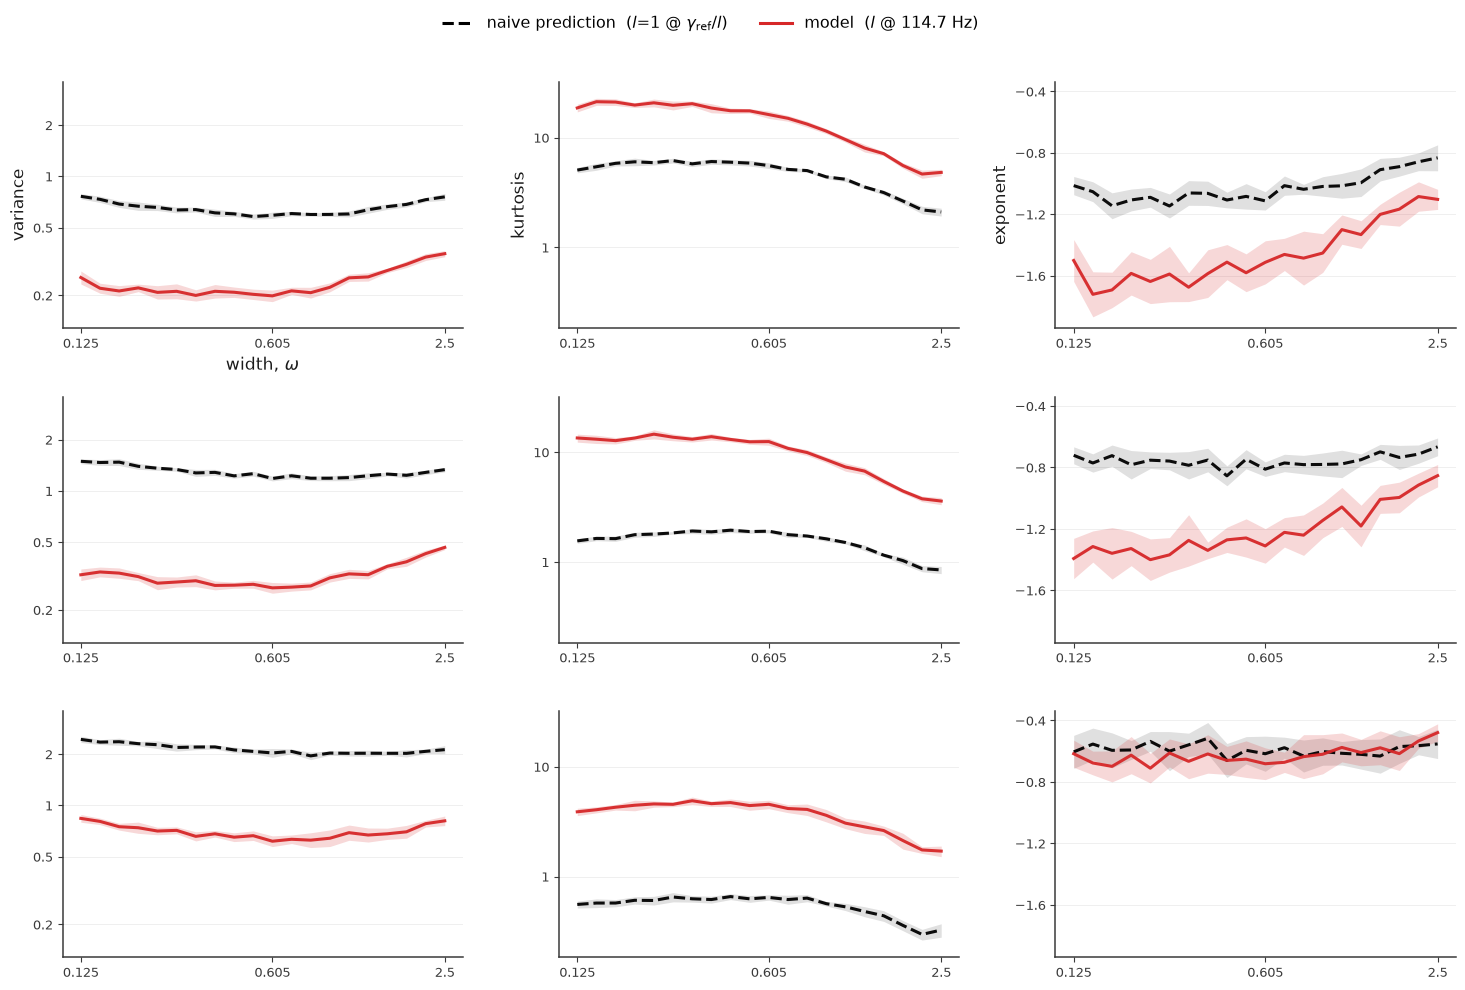

In [34]:
# ---- Visual comparison: prediction vs model, means over seeds with 95% bands ----
#
# Columns: variance, kurtosis, exponent   |   Rows: l = 2, 4, 8
# Dashed black = naive prediction (l=1 @ γ_ref/l, interpolated)
# Solid red    = model (l @ γ_ref)
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker

mpl.rcParams.update({
    'axes.spines.right':  False,
    'axes.spines.top':    False,
    'axes.edgecolor':     '#3a3a3a',
    'axes.linewidth':     1.1,
    'axes.labelcolor':    '#1a1a1a',
    'xtick.color':        '#3a3a3a',
    'ytick.color':        '#3a3a3a',
    'font.size':          11,
})

COLOR_BAYS = '#000000'   # black — prediction
COLOR_GP   = '#D62728'   # red   — model

quantities = [('variance', 'var'), ('kurtosis', 'kur'), ('exponent', 'exp')]
set_sizes_compare = [2, 4, 8]
ncols, nrows = len(quantities), len(set_sizes_compare)


def _summary(stack, q_key):
    """Mean over seeds (geometric for variance) with a 95% CI band."""
    if q_key == 'var':
        m, lo, hi = mean_ci(np.log(np.where(stack > 0, stack, np.nan)))
        return np.exp(m), np.exp(lo), np.exp(hi)
    return mean_ci(stack)


def _log_ticks(lo, hi):
    """At least two labelled ticks on a log axis spanning [lo, hi]."""
    k0, k1 = int(np.floor(np.log10(lo))), int(np.ceil(np.log10(hi)))
    ticks = [10.0 ** k for k in range(k0, k1 + 1) if lo <= 10.0 ** k <= hi]
    if len(ticks) < 2:
        ticks = [m * 10.0 ** k for k in range(k0 - 1, k1 + 1) for m in (1, 2, 5)
                 if lo <= m * 10.0 ** k <= hi]
    if len(ticks) < 2:
        ticks = [lo, hi]
    while len(ticks) > 6:
        ticks = ticks[::2]
    return ticks


fig = plt.figure(figsize=(5.4 * ncols, 3.6 * nrows))
gs  = fig.add_gridspec(nrows, ncols, hspace=0.28, wspace=0.24,
                       left=0.10, right=0.96, top=0.90, bottom=0.09)
_xtick_vals = [omegas[0], omegas[len(omegas) // 2], omegas[-1]]
AXIS_SCALES = {}

for col_idx, (q_name, q_key) in enumerate(quantities):
    curves = {}
    all_vals = []
    for l in set_sizes_compare:
        r = next(rr for rr in results_table if rr['l'] == l)
        curves[l] = (_summary(r[f'{q_name}_pred_seeds'], q_key),
                     _summary(r[f'{q_name}_meas_seeds'], q_key))
        for trip in curves[l]:
            all_vals += [np.ravel(t) for t in trip]
    all_vals = np.concatenate(all_vals)
    all_vals = all_vals[np.isfinite(all_vals)]
    use_log = (q_key != 'exp') and all_vals.size > 0 and all_vals.min() > 0
    AXIS_SCALES[q_name] = 'log' if use_log else 'linear'
    if use_log:
        lo, hi = all_vals.min() * 0.7, all_vals.max() * 1.4
    else:
        span = all_vals.max() - all_vals.min()
        pad = 0.05 * span if span > 0 else 0.1
        lo, hi = all_vals.min() - pad, all_vals.max() + pad

    for row_idx, l in enumerate(set_sizes_compare):
        ax = fig.add_subplot(gs[row_idx, col_idx])
        (pm, plo, phi), (mm, mlo, mhi) = curves[l]
        ax.fill_between(omegas, plo, phi, color=COLOR_BAYS, alpha=0.12, lw=0, zorder=2)
        ax.fill_between(omegas, mlo, mhi, color=COLOR_GP, alpha=0.18, lw=0, zorder=2)
        ax.plot(omegas, pm, color=COLOR_BAYS, linestyle='--', linewidth=2.2, alpha=0.95, zorder=3)
        ax.plot(omegas, mm, color=COLOR_GP, linestyle='-', linewidth=2.2, alpha=0.95, zorder=3)

        ax.set_xscale('log', base=2)
        ax.set_xticks(_xtick_vals)
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _p: f'{v:.3g}'))
        ax.xaxis.set_minor_locator(mticker.NullLocator())
        if use_log:
            ax.set_yscale('log')
            ax.set_ylim(lo, hi)
            ax.yaxis.set_major_locator(mticker.FixedLocator(_log_ticks(lo, hi)))
            ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _p: f'{v:g}'))
            ax.yaxis.set_minor_locator(mticker.NullLocator())
        else:
            ax.set_ylim(lo, hi)
            ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=5, min_n_ticks=2))

        ax.grid(True, axis='y', which='major', linestyle='-', linewidth=0.6, color='#ECECEC')
        ax.set_axisbelow(True)
        if row_idx == 0 and col_idx == 0:
            ax.set_xlabel(r'width, $\omega$', fontsize=12.5)
        if row_idx == 0:
            ax.set_ylabel(q_name, fontsize=12.5)
        ax.tick_params(labelsize=9.5)

legend_handles = [
    mpl.lines.Line2D([], [], color=COLOR_BAYS, linestyle='--', linewidth=2.2,
                     label=r'naive prediction  ($l$=1 @ $\gamma_{\mathrm{ref}}/l$)'),
    mpl.lines.Line2D([], [], color=COLOR_GP, linestyle='-', linewidth=2.2,
                     label=rf'model  ($l$ @ {gamma_ref:.1f} Hz)'),
]
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.975),
           ncol=2, frameon=False, fontsize=11.5)

_cA_path = OUTPUT_DIR / f'fig1_equivalence_{MODEL}_M{M}_{DISTRIBUTION}_{N_SEEDS}seeds.png'
plt.savefig(_cA_path, dpi=150, bbox_inches='tight')
THESIS_FIG_DIR = Path(PROJECT_ROOT) / 'simulated_experiments' / 'thesis_figures' / 'experiment_1'
THESIS_FIG_DIR.mkdir(parents=True, exist_ok=True)
_thesis_cA = THESIS_FIG_DIR / ('fig_1_metrics.png' if DISTRIBUTION == 'gamma'
                               else f'fig_1_metrics_{DISTRIBUTION}.png')
plt.savefig(_thesis_cA, dpi=150, bbox_inches='tight')
print(f'Saved {_cA_path}\nSaved {_thesis_cA}')
print(f'  For the caption: width on a logarithmic axis; y-axes: variance {AXIS_SCALES["variance"]}, '
      f'kurtosis {AXIS_SCALES["kurtosis"]}, exponent {AXIS_SCALES["exponent"]}. Lines are means over '
      f'{N_SEEDS} population seeds (geometric for variance), bands are 95% confidence intervals.')
plt.show()

## Appendix figure — how much each pixel varies between population draws

Same 4 × 3 layout as the heatmaps. For variance and kurtosis each pixel shows the 95%
confidence half-width across seeds as a percentage of the mean (for variance, on the log
scale: the factor by which the geometric mean is uncertain); for the exponent, which is
near zero in places, it shows the half-width in the exponent's own units.

Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_1/20261021/M_sparse_broad_1000_gp/090443/fig1_seed_variability_gp_M1000_M_sparse_broad_10seeds.png
Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_1/fig_1_seed_variability_M_sparse_broad.png
  For the caption: width and gain axes logarithmic; colour = 95% CI half-width across 10 seeds (variance and kurtosis: % of the mean, clipped at 50%; exponent: absolute, clipped at 0.5). Rows l = 1, 2, 4, 8; columns variance, kurtosis, exponent.


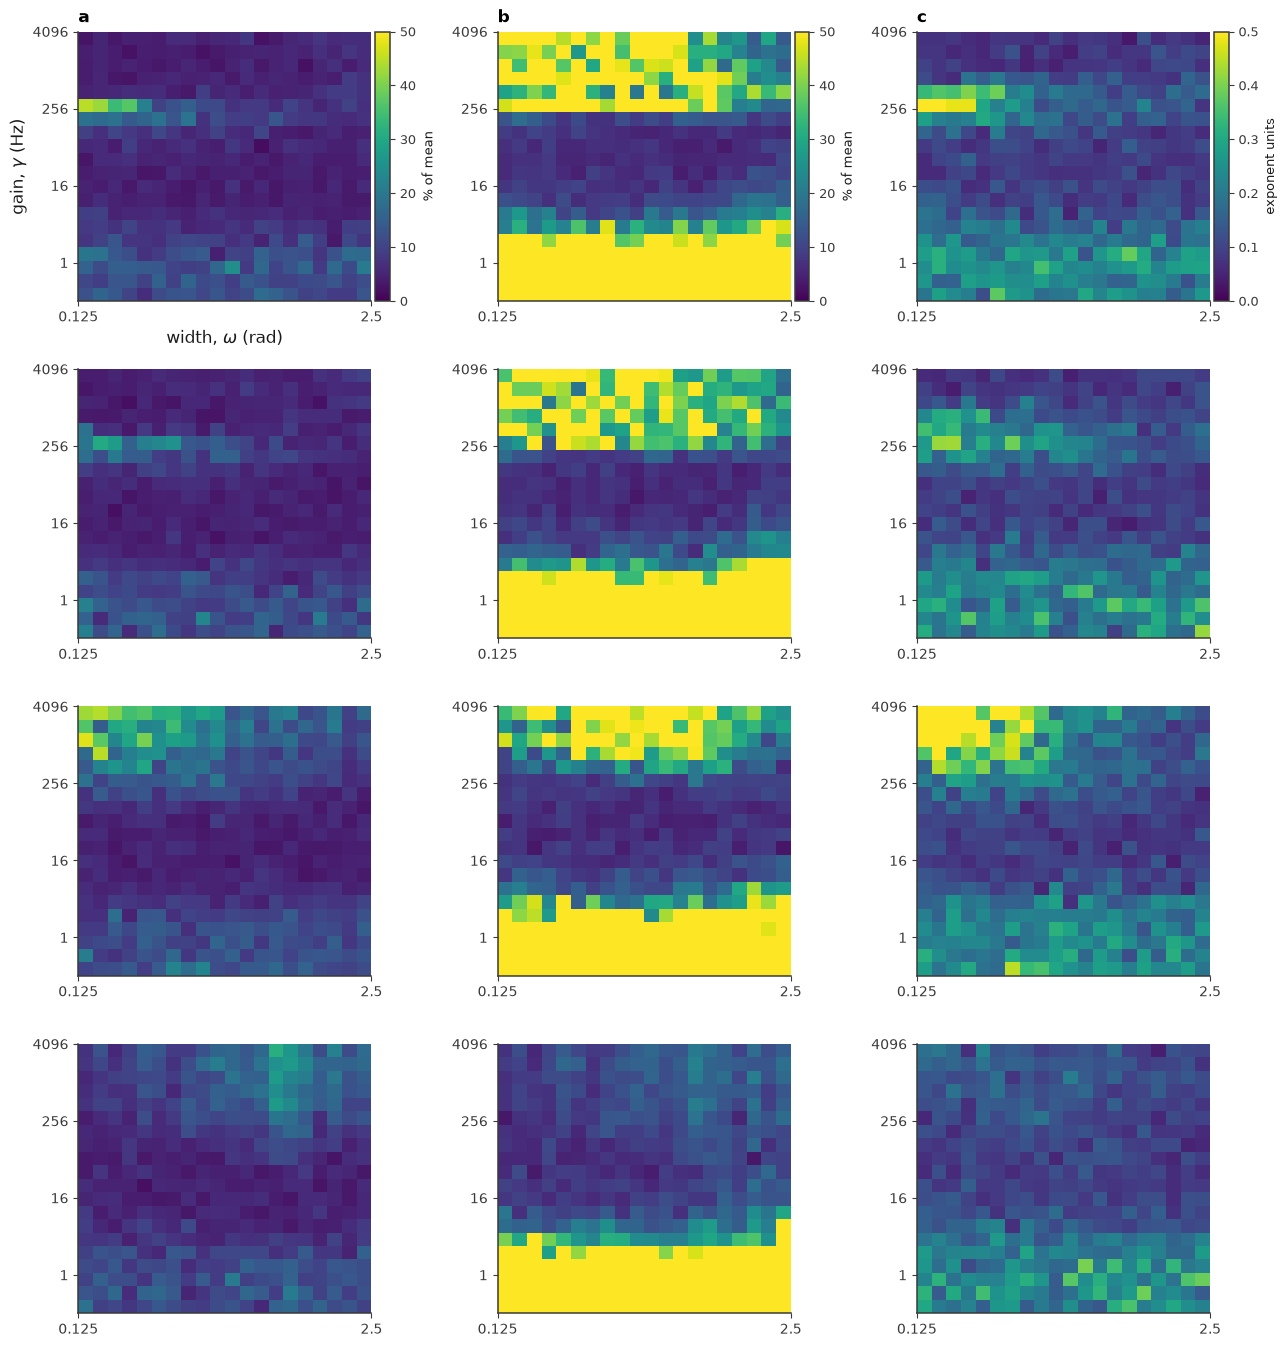

In [35]:
# ---- Appendix: between-seed variability of every heatmap pixel ----
import matplotlib as mpl
import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1 import make_axes_locatable

t_crit = stats.t.ppf(0.975, N_SEEDS - 1)


def _halfwidth_map(stack, key):
    with np.errstate(divide='ignore', invalid='ignore'):
        if key == 'var':
            lv = np.log(np.where(stack > 0, stack, np.nan))
            return 100 * (np.exp(t_crit * np.nanstd(lv, axis=0, ddof=1) / np.sqrt(N_SEEDS)) - 1)
        half = t_crit * np.nanstd(stack, axis=0, ddof=1) / np.sqrt(N_SEEDS)
        if key == 'kur':
            return 100 * half / np.abs(np.nanmean(stack, axis=0))
        return half

VMAP_SPEC = [('var', 0, 50, '% of mean'), ('kur', 0, 50, '% of mean'), ('exp', 0, 0.5, 'exponent units')]
ext = [np.log2(omegas[0]), np.log2(omegas[-1]), np.log2(gammas_total[0]), np.log2(gammas_total[-1])]
Y_TICKS_V = np.array([1, 16, 256, 4096])

nrows = len(SET_SIZES_HEATMAP)
fig, axes = plt.subplots(nrows, 3, figsize=(13, 3.4 * nrows))
for row_idx, l in enumerate(SET_SIZES_HEATMAP):
    for col_idx, (key, vmin, vmax, unit) in enumerate(VMAP_SPEC):
        ax = axes[row_idx, col_idx]
        hw = _halfwidth_map(heatmaps_seeds[l][key], key)
        im = ax.imshow(np.clip(hw, vmin, vmax), origin='lower', aspect='auto', extent=ext,
                       cmap='viridis', vmin=vmin, vmax=vmax, interpolation='nearest')
        cax = make_axes_locatable(ax).append_axes('right', size='5%', pad=0.04)
        if row_idx == 0:
            cb = fig.colorbar(im, cax=cax)
            cb.ax.tick_params(labelsize=9)
            cb.set_label(unit, fontsize=9)
        else:
            cax.axis('off')
        ax.set_xticks([np.log2(omegas[0]), np.log2(omegas[-1])])
        ax.set_xticklabels([f'{omegas[0]:g}', f'{omegas[-1]:g}'], fontsize=10)
        yt = Y_TICKS_V[(Y_TICKS_V >= gammas_total[0] * 0.9) & (Y_TICKS_V <= gammas_total[-1] * 1.1)]
        ax.set_yticks(np.log2(yt))
        ax.set_yticklabels([f'{v:g}' for v in yt], fontsize=10)
        if row_idx == 0 and col_idx == 0:
            ax.set_xlabel(r'width, $\omega$ (rad)', fontsize=12)
            ax.set_ylabel(r'gain, $\gamma$ (Hz)', fontsize=12)
        if row_idx == 0:
            ax.text(0.0, 1.02, 'abc'[col_idx], transform=ax.transAxes, fontsize=12,
                    fontweight='bold', va='bottom', ha='left')
plt.tight_layout()
_vm_name = ('fig_1_seed_variability.png' if DISTRIBUTION == 'gamma'
            else f'fig_1_seed_variability_{DISTRIBUTION}.png')
for path in (OUTPUT_DIR / f'fig1_seed_variability_{MODEL}_M{M}_{DISTRIBUTION}_{N_SEEDS}seeds.png',
             THESIS_FIG_DIR / _vm_name):
    plt.savefig(path, dpi=150, bbox_inches='tight', pad_inches=0.4)
    print(f'Saved {path}')
print(f'  For the caption: width and gain axes logarithmic; colour = 95% CI half-width across '
      f'{N_SEEDS} seeds (variance and kurtosis: % of the mean, clipped at 50%; exponent: absolute, '
      f'clipped at 0.5). Rows l = 1, 2, 4, 8; columns variance, kurtosis, exponent.')
plt.show()

#### Save results to CSV

One row per (set size, statistic): ρ, rMAE and the average departure, each as a mean with
its 95% confidence interval across seeds, plus the Holm-corrected p-value. Rows are
appended to `result_data/experiment_1/fit_log_seeds.csv` (new columns, so a new file) and
a standalone copy goes into this run's `OUTPUT_DIR`, together with every seed's heatmaps.

In [36]:
# ---- Save equivalence statistics + per-seed heatmaps ----
import uuid
import datetime as _dt
import pandas as pd

RUN_UUID = str(uuid.uuid4())
_timestamp = _dt.datetime.now().isoformat(timespec='seconds')
_n_high = N_HIGH if DISTRIBUTION == 'M_sparse_broad' else np.nan

_rows = []
for r in results_table:
    for q_name, q_key in quantities:
        rho, rmae, dep = r[f'{q_name}_rho'], r[f'{q_name}_rmae'], r[f'{q_name}_depart']
        _rows.append({
            'uuid': RUN_UUID, 'timestamp': _timestamp, 'M': M, 'distribution': DISTRIBUTION,
            'n_high': _n_high, 'n_seeds': N_SEEDS, 'n_trials_per_seed': N_TRIALS_PER_SEED,
            'model': MODEL, 'gamma_ref': gamma_ref, 'set_size': r['l'], 'g_eff': r['g_eff'],
            'metric': q_name,
            'rho_mean': rho[0], 'rho_ci_lo': rho[1], 'rho_ci_hi': rho[2],
            'rmae_mean': rmae[0], 'rmae_ci_lo': rmae[1], 'rmae_ci_hi': rmae[2],
            'departure_mean': dep[0], 'departure_ci_lo': dep[1], 'departure_ci_hi': dep[2],
            'departure_kind': 'mean log(model/prediction)' if q_key == 'var' else 'mean (model - prediction)',
            'p_holm': r[f'{q_name}_p_holm'],
        })
fits_df = pd.DataFrame(_rows)

_run_csv = OUTPUT_DIR / f'equivalence_{RUN_UUID[:8]}.csv'
fits_df.to_csv(_run_csv, index=False)
_log_csv = RESULT_BASE / EXPERIMENT_TAG / 'fit_log_seeds.csv'
_log_csv.parent.mkdir(parents=True, exist_ok=True)
fits_df.to_csv(_log_csv, mode='a', header=not _log_csv.exists(), index=False)

_npz = OUTPUT_DIR / f'heatmaps_by_seed_{MODEL}_M{M}_{DISTRIBUTION}_{N_SEEDS}seeds.npz'
np.savez_compressed(_npz, omegas=omegas, gammas_total=gammas_total,
                    **{f'l{l}_{k}': heatmaps_seeds[l][k] for l in SET_SIZES_HEATMAP for k in KEYS})

print(f"Run UUID: {RUN_UUID}")
print(f"  Wrote {len(fits_df)} rows -> {_run_csv}")
print(f"  Appended to: {_log_csv}")
print(f"  Per-seed heatmaps: {_npz}")
fits_df

Run UUID: 016252a7-fea6-491c-bcc9-8668cf5a9d14
  Wrote 9 rows -> /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_1/20261021/M_sparse_broad_1000_gp/090443/equivalence_016252a7.csv
  Appended to: /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_1/fit_log_seeds.csv
  Per-seed heatmaps: /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_1/20261021/M_sparse_broad_1000_gp/090443/heatmaps_by_seed_gp_M1000_M_sparse_broad_10seeds.npz


,uuid,timestamp,M,distribution,n_high,n_seeds,n_trials_per_seed,model,gamma_ref,set_size,...,rho_ci_lo,rho_ci_hi,rmae_mean,rmae_ci_lo,rmae_ci_hi,departure_mean,departure_ci_lo,departure_ci_hi,departure_kind,p_holm
0,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,2,...,0.384120,0.656531,0.632875,0.630079,0.635671,-1.016317,-1.024595,-1.008039,mean log(model/prediction),4.658978e-18
1,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,2,...,0.865686,0.927533,2.030678,1.975972,2.085383,9.749858,9.512783,9.986933,mean (model - prediction),3.884728e-14
2,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,2,...,0.341927,0.595307,0.421568,0.400325,0.442811,-0.431242,-0.450896,-0.411587,mean (model - prediction),8.232682e-12
3,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,4,...,0.085882,0.249824,0.751104,0.748136,0.754071,-1.401624,-1.414107,-1.389140,mean log(model/prediction),9.255390e-18
4,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,4,...,0.823749,0.880772,5.525624,5.399311,5.651937,8.741161,8.578482,8.903840,mean (model - prediction),4.384386e-15
5,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,4,...,0.026524,0.363438,0.603907,0.574090,0.633725,-0.455250,-0.476018,-0.434481,mean (model - prediction),8.232682e-12
6,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,8,...,0.235742,0.426635,0.671332,0.667435,0.675230,-1.117770,-1.129699,-1.105841,mean log(model/prediction),4.123358e-17
7,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,8,...,0.714164,0.811175,5.826260,5.656138,5.996381,3.196510,3.155139,3.237882,mean (model - prediction),2.004443e-16
8,016252a7-fea6-491c-bcc9-8668cf5a9d14,2026-10-21T10:45:55,1000,M_sparse_broad,1,10,1000,gp,114.730508,8,...,-0.177015,0.033483,0.282463,0.261100,0.303826,-0.037299,-0.063189,-0.011409,mean (model - prediction),9.853958e-03


In [37]:
# Print LaTeX rows for tab:equivalence (mean [95% CI] across seeds)
_p = lambda p: '$<0.001$' if p < 0.001 else f'{p:.3f}'
for r in results_table:
    for q_name, q_key in quantities:
        rho, rmae, dep = r[f'{q_name}_rho'], r[f'{q_name}_rmae'], r[f'{q_name}_depart']
        if q_key == 'var':
            dep_txt = f"$\\times${np.exp(dep[0]):.2f} [{np.exp(dep[1]):.2f}, {np.exp(dep[2]):.2f}]"
        else:
            dep_txt = f"${dep[0]:+.2f}$ [${dep[1]:+.2f}$, ${dep[2]:+.2f}$]"
        print(f"{r['l']} & {q_name} & {rho[0]:.2f} [{rho[1]:.2f}, {rho[2]:.2f}] & "
              f"{100*rmae[0]:.0f}\\% [{100*rmae[1]:.0f}, {100*rmae[2]:.0f}] & "
              f"{dep_txt} & {_p(r[f'{q_name}_p_holm'])} \\\\")

2 & variance & 0.52 [0.38, 0.66] & 63\% [63, 64] & $\times$0.36 [0.36, 0.36] & $<0.001$ \\
2 & kurtosis & 0.90 [0.87, 0.93] & 203\% [198, 209] & $+9.75$ [$+9.51$, $+9.99$] & $<0.001$ \\
2 & exponent & 0.47 [0.34, 0.60] & 42\% [40, 44] & $-0.43$ [$-0.45$, $-0.41$] & $<0.001$ \\
4 & variance & 0.17 [0.09, 0.25] & 75\% [75, 75] & $\times$0.25 [0.24, 0.25] & $<0.001$ \\
4 & kurtosis & 0.85 [0.82, 0.88] & 553\% [540, 565] & $+8.74$ [$+8.58$, $+8.90$] & $<0.001$ \\
4 & exponent & 0.19 [0.03, 0.36] & 60\% [57, 63] & $-0.46$ [$-0.48$, $-0.43$] & $<0.001$ \\
8 & variance & 0.33 [0.24, 0.43] & 67\% [67, 68] & $\times$0.33 [0.32, 0.33] & $<0.001$ \\
8 & kurtosis & 0.76 [0.71, 0.81] & 583\% [566, 600] & $+3.20$ [$+3.16$, $+3.24$] & $<0.001$ \\
8 & exponent & -0.07 [-0.18, 0.03] & 28\% [26, 30] & $-0.04$ [$-0.06$, $-0.01$] & 0.010 \\
